# Lab 9: Training an RL Agent

The question I'm working on: with the same CartPole and the same budget of 20,000 steps, which agent learns best, and which parts of DQN actually matter? I write DQN, two broken versions of it, REINFORCE with a baseline and PPO from scratch, using the starter unchanged for the environment, the networks and the measuring. Every agent runs on seeds 0, 1 and 2.

One detail matters all the way through: an episode can end because the pole fell (terminated) or because it hit the 200-step limit (truncated). Those aren't the same thing, and the best possible return is 200.

In [1]:
import copy
import hashlib
import json
import math
import os
import subprocess
import sys
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import lab09_starter as S

torch.set_num_threads(1)          # tiny networks: one thread is faster and makes runs bit-reproducible

SEEDS = [0, 1, 2]
BUDGET = S.BUDGET                 # 20,000 environment steps for every agent
LEVEL = 150                       # "first step at which the smoothed return reaches 150"
# DQN (piece 2)
DQN_SETTINGS = dict(eps_start=1.0, eps_end=0.05, eps_decay_steps=8000, buffer_capacity=20000, warmup=500,
                    batch_size=64, learning_rate=1e-3, gamma=0.99, grad_clip=10.0, target_every=250)
# REINFORCE and PPO (piece 4)
REINFORCE_SETTINGS = dict(episodes_per_update=8, policy_lr=3e-3, value_lr=1e-2, gamma=0.99)
PPO_SETTINGS = dict(rollout_steps=1024, epochs=6, minibatch_size=128, clip=0.2, gamma=0.99, lam=0.95,
                    learning_rate=3e-4, value_coef=0.5, grad_clip=0.5, entropy_coef=0.0)
Q_PROBE_EVERY = 1000
Q_BOUND = 1.0 / (1.0 - DQN_SETTINGS["gamma"])   # 100
PROBES = S.probe_states()          # 500 fixed states, collected once before any training, shared by every run
assert tuple(PROBES.shape) == (500, 4)
os.makedirs("figures", exist_ok=True)
results = {"settings": {"dqn": DQN_SETTINGS, "reinforce": REINFORCE_SETTINGS, "ppo": PPO_SETTINGS,
                        "q_probe_every": Q_PROBE_EVERY, "q_bound": Q_BOUND, "level": LEVEL,
                        "seeds": SEEDS, "budget": BUDGET,
                        "torch_threads": torch.get_num_threads(), "torch_version": torch.__version__},
           "piece_seconds": {}, "checks": {}, "runs": {}}
results["probe_states_sha256"] = hashlib.sha256(PROBES.numpy().tobytes()).hexdigest()
notebook_start = time.perf_counter()
print("probe states:", tuple(PROBES.shape), "sha256", results["probe_states_sha256"][:16])

probe states: (500, 4) sha256 2037ff1df2cdef2f


In [2]:
def to_jsonable(x):
    """nan/inf -> None, numpy -> python, recursively."""
    if isinstance(x, dict):
        return {str(key): to_jsonable(value) for key, value in x.items()}
    if isinstance(x, (list, tuple)):
        return [to_jsonable(value) for value in x]
    if isinstance(x, np.ndarray):
        return to_jsonable(x.tolist())
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (float, np.floating)):
        return float(x) if np.isfinite(x) else None
    return x

def make_run_record(episodes, wall_seconds, **extras):
    curve = S.smooth_curve(episodes)
    return {"episodes": [[int(t), float(r)] for t, r in episodes],
            "curve": [None if not np.isfinite(v) else float(v) for v in curve],
            "final_return": S.final_return(episodes),
            "steps_to_150": S.steps_to_reach(curve, LEVEL),
            "n_episodes": len(episodes), "total_env_steps": BUDGET, "wall_seconds": wall_seconds, **extras}

def curve_array(record):
    return np.array([np.nan if v is None else v for v in record["curve"]])

def save_results(results, path="lab9_results.json"):
    with open(path, "w") as results_file:
        json.dump(to_jsonable(results), results_file, indent=1)

def show(fig, path=None):
    """Save the figure if a path is given, and display it when running in a notebook."""
    if path is not None:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    if "ipykernel" in sys.modules:
        import io
        from IPython.display import Image, display
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    plt.close(fig)

## Run the starter once

Before writing anything I run the starter as given, to check the environment and to see what a random policy scores.

In [3]:
starter_run = subprocess.run([sys.executable, "lab09_starter.py"], capture_output=True, text=True, check=True)
print(starter_run.stdout)
results["starter"] = {"stdout": starter_run.stdout.strip(),
                      "random_mean_return": float(starter_run.stdout.split("mean return ")[1].split()[0])}

random policy: mean return 22.2 over 50 episodes (best possible is 200)
probe states: (500, 4)
saved starter_check.png



A random policy averages 22.2 over 50 episodes, a long way from 200. The starter also gives 500 probe states. I take them once, before any training, so every agent and seed has its Q-values measured on the same states.

## Piece 1: the losses, written and checked

Every agent depends on a few small formulas, and a wrong one usually still trains, just badly. So before any agent runs I check each one against numbers I can work out by hand.

In [4]:
def stored_done_flag(terminated, truncated):
    """Flag stored with a transition. Only a true terminal (pole fell / cart left) stops the bootstrap.
    A time-limit truncation is not terminal: the state still has a future, the episode was just cut."""
    return float(terminated)

def dqn_target(rewards, next_q_values, dones, gamma):
    """y_i = r_i + gamma * (1 - done_i) * max_a' Q(s'_i, a').
    rewards, dones: (B,) float32. next_q_values: (B, n_actions) from the bootstrap network,
    which the CALLER computes inside torch.no_grad(). Returns (B,)."""
    return rewards + gamma * (1.0 - dones) * next_q_values.max(dim=1).values

def huber_loss(errors, delta=1.0):
    """Elementwise Huber: 0.5 e^2 if |e| <= delta, else delta * (|e| - 0.5 delta). No reduction."""
    abs_errors = errors.abs()
    return torch.where(abs_errors <= delta, 0.5 * errors ** 2, delta * (abs_errors - 0.5 * delta))

def ppo_clip_objective(ratio, advantages, clip=0.2):
    """Per-sample PPO surrogate, higher is better: min(r * A, clip(r, 1 - eps, 1 + eps) * A)."""
    return torch.minimum(ratio * advantages, torch.clamp(ratio, 1 - clip, 1 + clip) * advantages)

def returns_to_go(rewards, gamma):
    """G_t = r_t + gamma * G_{t+1}, G after the last reward = 0. Returns float32 numpy array."""
    running_return, out = 0.0, np.zeros(len(rewards), np.float32)
    for i in reversed(range(len(rewards))):
        running_return = rewards[i] + gamma * running_return
        out[i] = running_return
    return out

def gae_advantages(rewards, values, next_values, terminated, episode_ended, gamma, lam):
    """Generalized advantage estimation over one rollout (numpy float32 arrays, length n).
    values[i] = V(s_i); next_values[i] = V(s_{i+1}) where s_{i+1} is the state step() returned
    (BEFORE any reset), computed at collection time under no_grad.
    delta_i = r_i + gamma * (1 - terminated_i) * next_values[i] - values[i]
    A_i     = delta_i + gamma * lam * (1 - episode_ended_i) * A_{i+1},  with A_n = 0.
    episode_ended_i = terminated_i or truncated_i (the recursion must not cross an episode boundary,
    but a truncated step still bootstraps through next_values[i]). Returns advantages (n,)."""
    advantages = np.zeros(len(rewards), np.float32)
    next_advantage = 0.0
    for i in reversed(range(len(rewards))):
        delta = rewards[i] + gamma * (1.0 - terminated[i]) * next_values[i] - values[i]
        next_advantage = delta + gamma * lam * (1.0 - episode_ended[i]) * next_advantage
        advantages[i] = next_advantage
    return advantages

### Check 1: when the target bootstraps

The DQN target is r + gamma × max Q(next state), unless the episode really ended. The trap is the time limit: reaching step 200 isn't the pole falling, so the target should still bootstrap. I test four cases with reward 1, a next value of 7 and discount 0.9, next to the two ways of getting it wrong.

In [5]:
rewards = torch.tensor([1.0, 1.0, 1.0, 1.0])
next_q = torch.tensor([[7.0, 2.0]] * 4)            # largest next value 7
cases = [("terminal (pole fell)", True, False),
         ("non-terminal", False, False),
         ("time limit only (truncated)", False, True),
         ("pole fell on step 200 (both flags)", True, True)]
dones = torch.tensor([stored_done_flag(term, trunc) for _, term, trunc in cases])
targets = dqn_target(rewards, next_q, dones, gamma=0.9)
expected = [1.0, 7.3, 7.3, 1.0]
# the BUG versions: truncation treated as terminal, and a true terminal that still bootstraps
bug_truncation_dones = torch.tensor([float(term or trunc) for _, term, trunc in cases])
bug_truncation_targets = dqn_target(rewards, next_q, bug_truncation_dones, gamma=0.9)
bug_no_terminal_targets = dqn_target(rewards, next_q, torch.zeros(4), gamma=0.9)
print("reward 1, largest next value 7, discount 0.9")
print(f"{'case':38s} {'stored done':>11s} {'target':>9s} {'expected':>9s} {'bug: trunc=terminal':>20s} {'bug: never terminal':>20s}")
for i, (name, term, trunc) in enumerate(cases):
    print(f"{name:38s} {float(dones[i]):11.1f} {float(targets[i]):9.6f} {expected[i]:9.6f} "
          f"{float(bug_truncation_targets[i]):20.6f} {float(bug_no_terminal_targets[i]):20.6f}")
bootstrap_error = max(abs(float(targets[i]) - expected[i]) for i in range(4))
bootstrap_passed = bootstrap_error < 1e-5
print("max |target - expected| =", f"{bootstrap_error:.2e}", "->", "PASS" if bootstrap_passed else "FAIL")
results["checks"]["bootstrap"] = {"cases": [c[0] for c in cases], "targets": targets.tolist(), "expected": expected,
                                  "bug_truncation_as_terminal": bug_truncation_targets.tolist(),
                                  "bug_always_bootstrap": bug_no_terminal_targets.tolist(),
                                  "passed": bool(bootstrap_passed)}

reward 1, largest next value 7, discount 0.9
case                                   stored done    target  expected  bug: trunc=terminal  bug: never terminal
terminal (pole fell)                           1.0  1.000000  1.000000             1.000000             7.300000
non-terminal                                   0.0  7.300000  7.300000             7.300000             7.300000
time limit only (truncated)                    0.0  7.300000  7.300000             1.000000             7.300000
pole fell on step 200 (both flags)             1.0  1.000000  1.000000             1.000000             7.300000
max |target - expected| = 2.86e-07 -> PASS


The non-terminal and time-limit cases both give 1 + 0.9 × 7 = 7.3, and only a real terminal gives 1.0, so the target is right. The two bugs show why it matters:

- **Truncation stored as terminal:** the same state gets 1.0 at step 200 and 7.3 any other time. Time isn't part of the state, so the network sees contradictory targets.
- **Terminal that bootstraps:** falling is worth 7.3 instead of 1.0, so the agent never learns that falling ends the reward.

### Check 2: Huber loss

I compare my Huber loss with a hand calculation and with PyTorch's two built-in versions at errors of 0.5, 3 and -3, which covers both the quadratic and the linear part.

In [6]:
huber_errors = torch.tensor([0.5, 3.0, -3.0])
by_hand = [0.5 * 0.5 ** 2, 1.0 * (3.0 - 0.5), 1.0 * (3.0 - 0.5)]      # 0.125, 2.5, 2.5
mine = huber_loss(huber_errors)
torch_huber = F.huber_loss(huber_errors, torch.zeros(3), reduction="none", delta=1.0)
torch_smooth_l1 = F.smooth_l1_loss(huber_errors, torch.zeros(3), reduction="none", beta=1.0)
print(f"{'error':>6s} {'by hand':>9s} {'mine':>9s} {'F.huber_loss':>13s} {'F.smooth_l1_loss':>17s}")
for i in range(3):
    print(f"{float(huber_errors[i]):6.1f} {by_hand[i]:9.6f} {float(mine[i]):9.6f} {float(torch_huber[i]):13.6f} {float(torch_smooth_l1[i]):17.6f}")
huber_gap = max(float((mine - torch.tensor(by_hand)).abs().max()), float((mine - torch_huber).abs().max()),
                float((mine - torch_smooth_l1).abs().max()))
huber_passed = huber_gap < 1e-7
print("largest disagreement between the four:", f"{huber_gap:.2e}", "->", "PASS" if huber_passed else "FAIL")
results["checks"]["huber"] = {"errors": huber_errors.tolist(), "by_hand": by_hand, "mine": mine.tolist(),
                              "torch_huber": torch_huber.tolist(), "torch_smooth_l1": torch_smooth_l1.tolist(),
                              "largest_gap": huber_gap, "passed": bool(huber_passed)}

 error   by hand      mine  F.huber_loss  F.smooth_l1_loss
   0.5  0.125000  0.125000      0.125000          0.125000
   3.0  2.500000  2.500000      2.500000          2.500000
  -3.0  2.500000  2.500000      2.500000          2.500000
largest disagreement between the four: 0.00e+00 -> PASS


All four agree exactly: 0.125 at 0.5 and 2.5 at both 3 and -3, so it's symmetric and grows linearly past delta = 1. The handout doesn't give a delta, so I used 1, the PyTorch default.

### Check 3: the fixed point, with and without a target network

A single state that always returns to itself with reward 1 and discount 0.9 has a true value of exactly 10. I train Q on it for 3,000 updates twice: once with a target network refreshed every 50 updates, and once without one. That shows whether my target network works, and what it costs.

--- with_target (true value 10) ---
value at updates: 0: -0.0796, 50: 0.8917, 100: 1.8231, 200: 3.3403, 500: 6.4496, 1000: 8.7642, 1500: 9.5680, 2000: 9.8490, 2500: 9.9476, 3000: 9.9827
final 9.9827   mean of last 100 9.9779   last 500 min 9.8897 max 10.0575
first update with |value - 10| < 0.1: 2101   target refreshes: 60


--- without_target (true value 10) ---
value at updates: 0: -0.0796, 50: 10.4150, 100: 9.9459, 200: 10.0003, 500: 10.0000, 1000: 10.0000, 1500: 10.0000, 2000: 10.0000, 2500: 10.0000, 3000: 10.0000
final 10.0000   mean of last 100 10.0000   last 500 min 10.0000 max 10.0000
first update with |value - 10| < 0.1: 15   target refreshes: 0
target arm criterion (|mean last 100 - 10| < 0.5 and 60 refreshes): PASS (the no-target arm has no pass criterion)


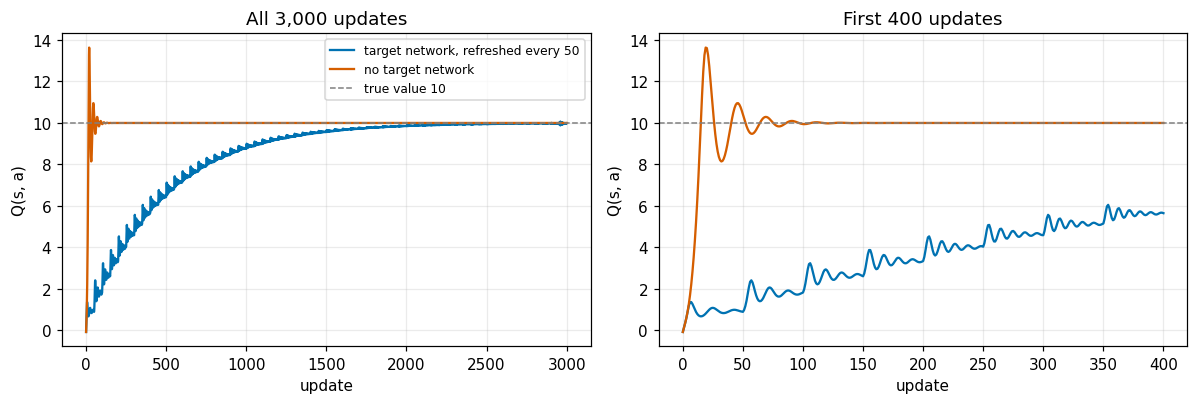

In [7]:
def fixed_point_run(use_target, n_updates=3000, refresh_every=50, learning_rate=0.01, gamma=0.9, seed=0):
    """One state, one action, reward 1, next state = same state, never terminal. True value 1/(1-0.9) = 10.
    Returns the value Q(s, a) after every update (length n_updates + 1, index 0 = before training)
    and the number of target refreshes."""
    S.set_seed(seed)
    q_net = S.QNet(n_actions=1)                      # one action, so max over actions is that action
    target_net = copy.deepcopy(q_net)
    optimizer = torch.optim.Adam(q_net.parameters(), lr=learning_rate)
    state = PROBES[0:1].clone()                      # a real CartPole state, fixed
    action = torch.tensor([0]); reward = torch.tensor([1.0]); done = torch.tensor([0.0])
    n_refreshes = 0
    with torch.no_grad():
        values = [float(q_net(state)[0, 0])]
    for update in range(1, n_updates + 1):
        with torch.no_grad():
            bootstrap_net = target_net if use_target else q_net
            target = dqn_target(reward, bootstrap_net(state), done, gamma)
        prediction = q_net(state).gather(1, action[:, None])[:, 0]
        loss = huber_loss(prediction - target).mean()
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        if use_target and update % refresh_every == 0:
            target_net.load_state_dict(q_net.state_dict())
            n_refreshes += 1
        with torch.no_grad():
            values.append(float(q_net(state)[0, 0]))
    return values, n_refreshes

REPORT_UPDATES = [0, 50, 100, 200, 500, 1000, 1500, 2000, 2500, 3000]
fixed_point = {}
for arm_name, use_target in [("with_target", True), ("without_target", False)]:
    values, n_refreshes = fixed_point_run(use_target)
    values_array = np.array(values)
    within = np.where(np.abs(values_array - 10.0) < 0.1)[0]
    fixed_point[arm_name] = {
        "trajectory": values,
        "at_updates": {str(u): values[u] for u in REPORT_UPDATES},
        "final": values[-1], "mean_last_100": float(values_array[-100:].mean()),
        "min_last_500": float(values_array[-500:].min()), "max_last_500": float(values_array[-500:].max()),
        "first_update_within_0.1": int(within[0]) if len(within) else None,
        "n_refreshes": n_refreshes}
    record = fixed_point[arm_name]
    print(f"--- {arm_name} (true value 10) ---")
    print("value at updates:", ", ".join(f"{u}: {values[u]:.4f}" for u in REPORT_UPDATES))
    print(f"final {record['final']:.4f}   mean of last 100 {record['mean_last_100']:.4f}   "
          f"last 500 min {record['min_last_500']:.4f} max {record['max_last_500']:.4f}")
    print("first update with |value - 10| < 0.1:", record["first_update_within_0.1"] if len(within) else "never",
          "  target refreshes:", n_refreshes)
fixed_point_passed = (abs(fixed_point["with_target"]["mean_last_100"] - 10.0) < 0.5
                      and fixed_point["with_target"]["n_refreshes"] == 60
                      and fixed_point["without_target"]["n_refreshes"] == 0)
print("target arm criterion (|mean last 100 - 10| < 0.5 and 60 refreshes):", "PASS" if fixed_point_passed else "FAIL",
      "(the no-target arm has no pass criterion)")
results["checks"]["fixed_point"] = {"with_target": {k: v for k, v in fixed_point["with_target"].items() if k != "trajectory"},
                                    "without_target": {k: v for k, v in fixed_point["without_target"].items() if k != "trajectory"},
                                    "trajectory_with_target": fixed_point["with_target"]["trajectory"],
                                    "trajectory_without_target": fixed_point["without_target"]["trajectory"],
                                    "passed": bool(fixed_point_passed)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, x_limit in zip(axes, [3000, 400]):
    ax.plot(fixed_point["with_target"]["trajectory"][:x_limit + 1], color="#0072B2", label="target network, refreshed every 50")
    ax.plot(fixed_point["without_target"]["trajectory"][:x_limit + 1], color="#D55E00", label="no target network")
    ax.axhline(10.0, ls="--", color="grey", lw=1, label="true value 10")
    ax.set_xlabel("update"); ax.set_ylabel("Q(s, a)"); ax.grid(alpha=0.25)
axes[0].set_title("All 3,000 updates"); axes[1].set_title("First 400 updates"); axes[0].legend(fontsize=8)
fig.tight_layout()
show(fig, "figures/fixed_point.png")

**With a target network:** Q climbs in a staircase, one step per refresh, and reaches 9.98 by update 3,000. It first gets within 0.1 of 10 at update 2,101, after 60 refreshes in total.

**Without one:** I expected trouble and didn't get any. Q overshot to 13.6, dipped, and settled at exactly 10 by about update 130. A single state that bootstraps from itself just oscillates and converges.

So this check can't show the instability DQN has across many states, and I don't claim it does. What it does show is the cost of the target network: about 2,100 updates to converge instead of about 130.

### Check 4: PPO clipped objective

PPO's clip should stop the policy moving too far in the direction the advantage likes, but still fully punish a bad move. I check ratios of 1.3 and 0.7 with advantages of +1 and -1 against values I worked out by hand.

In [8]:
clip_ratios = torch.tensor([1.3, 1.3, 0.7, 0.7])
clip_advantages = torch.tensor([1.0, -1.0, 1.0, -1.0])
clip_by_hand = [1.2,    # min(1.3 * 1, 1.2 * 1) = min(1.3, 1.2)
                -1.3,   # min(1.3 * -1, 1.2 * -1) = min(-1.3, -1.2)
                0.7,    # min(0.7 * 1, 0.8 * 1) = min(0.7, 0.8)
                -0.8]   # min(0.7 * -1, 0.8 * -1) = min(-0.7, -0.8)
clip_mine = ppo_clip_objective(clip_ratios, clip_advantages, clip=0.2)
print(f"{'ratio':>6s} {'advantage':>10s} {'by hand':>9s} {'mine':>9s}")
for i in range(4):
    print(f"{float(clip_ratios[i]):6.1f} {float(clip_advantages[i]):10.1f} {clip_by_hand[i]:9.4f} {float(clip_mine[i]):9.4f}")
clip_gap = float((clip_mine - torch.tensor(clip_by_hand)).abs().max())
ppo_clip_passed = clip_gap < 1e-6
print("largest gap:", f"{clip_gap:.2e}", "->", "PASS" if ppo_clip_passed else "FAIL")
results["checks"]["ppo_clip"] = {"ratios": clip_ratios.tolist(), "advantages": clip_advantages.tolist(),
                                 "by_hand": clip_by_hand, "mine": clip_mine.tolist(), "passed": bool(ppo_clip_passed)}

 ratio  advantage   by hand      mine
   1.3        1.0    1.2000    1.2000
   1.3       -1.0   -1.3000   -1.3000
   0.7        1.0    0.7000    0.7000
   0.7       -1.0   -0.8000   -0.8000
largest gap: 0.00e+00 -> PASS


All four match. At ratio 1.3 with a positive advantage the objective is capped at 1.2, but with a negative advantage it stays at -1.3. Ratio 0.7 mirrors that (0.7 and -0.8). So the clip only removes the reward for overshooting and leaves the penalty side alone.

### Check 5: return-to-go

REINFORCE needs the discounted return from each step to the end of the episode. Rewards 1, 1, 1 with discount 0.5 should give 1.75, 1.5 and 1.0.

In [9]:
rtg_mine = returns_to_go([1.0, 1.0, 1.0], 0.5)
rtg_by_hand = [1.75, 1.5, 1.0]        # 1 + 0.5 * 1.5, 1 + 0.5 * 1, 1
print("rewards [1, 1, 1], discount 0.5")
print("mine:   ", [float(v) for v in rtg_mine])
print("by hand:", rtg_by_hand)
rtg_passed = bool(np.abs(rtg_mine - np.array(rtg_by_hand)).max() < 1e-6)
print("->", "PASS" if rtg_passed else "FAIL")
results["checks"]["return_to_go"] = {"mine": [float(v) for v in rtg_mine], "by_hand": rtg_by_hand, "passed": rtg_passed}

rewards [1, 1, 1], discount 0.5
mine:    [1.75, 1.5, 1.0]
by hand: [1.75, 1.5, 1.0]
-> PASS


It gives 1.75, 1.5 and 1.0, matching the hand calculation.

### Check 6 (extra): advantage estimation at episode ends

The handout doesn't ask for this, but GAE is where a time-limit bug would hide in PPO, so I check it the same way: a truncated step should still bootstrap from the next state's value, a terminated step shouldn't, and the recursion should never cross from one episode into the next.

In [10]:
gae_cases = [
    ("three steps, terminal at end", [1, 1, 1], [0, 0, 0], [0, 0, 1], [0, 0, 1], [1.3125, 1.25, 1.0]),
    ("truncated last step bootstraps", [1, 1], [0, 2], [0, 0], [0, 1], [1.5, 2.0]),
    ("terminated last step", [1, 1], [0, 0], [0, 1], [0, 1], [1.25, 1.0]),
    ("boundary after step 0", [1, 1], [0, 0], [1, 0], [1, 0], [1.0, 1.0]),
]
gae_passed = True
gae_rows = []
for name, case_rewards, case_next_values, case_terminated, case_ended, case_expected in gae_cases:
    got = gae_advantages(np.array(case_rewards, np.float32), np.zeros(len(case_rewards), np.float32),
                         np.array(case_next_values, np.float32), np.array(case_terminated, np.float32),
                         np.array(case_ended, np.float32), gamma=0.5, lam=0.5)
    case_ok = bool(np.abs(got - np.array(case_expected)).max() < 1e-6)
    gae_passed = gae_passed and case_ok
    gae_rows.append({"case": name, "mine": [float(v) for v in got], "expected": case_expected, "passed": case_ok})
    print(f"{name:34s} mine {[round(float(v), 4) for v in got]}  expected {case_expected}  {'PASS' if case_ok else 'FAIL'}")
results["checks"]["gae"] = {"cases": gae_rows, "passed": bool(gae_passed)}

three steps, terminal at end       mine [1.3125, 1.25, 1.0]  expected [1.3125, 1.25, 1.0]  PASS
truncated last step bootstraps     mine [1.5, 2.0]  expected [1.5, 2.0]  PASS
terminated last step               mine [1.25, 1.0]  expected [1.25, 1.0]  PASS
boundary after step 0              mine [1.0, 1.0]  expected [1.0, 1.0]  PASS


All four cases match. The truncated step bootstraps (1.5 and 2.0), the terminated one doesn't, and nothing leaks across the episode boundary.

### All checks

In [11]:
results["checks"]["all_passed"] = all(results["checks"][name]["passed"] for name in
    ["bootstrap", "huber", "fixed_point", "ppo_clip", "return_to_go", "gae"])
print("all piece 1 checks passed:", results["checks"]["all_passed"])
results["piece_seconds"]["checks"] = time.perf_counter() - notebook_start
save_results(results)
assert results["checks"]["all_passed"], "a piece 1 check failed: fix it before any agent runs"

all piece 1 checks passed: True


All six checks pass, so I move on to the agents. The fixed-point check only has a pass criterion for the target-network version; the no-target version is just reported.

## Piece 2: DQN, three seeds

Full DQN with the handout's settings: a replay buffer, epsilon decaying from 1.0 to 0.05 over 8,000 steps, a target network, Huber loss and gradients clipped at 10. Every 1,000 steps I also record the Q-values on the 500 probe states, so I can check them against the bound of 100 (a reward of 1 per step with discount 0.99 can't be worth more than 100).

In [12]:
class ReplayBuffer:
    """Numpy ring buffer of (state, action, reward, next_state, done)."""
    def __init__(self, capacity, obs_dim=4):
        self.capacity, self.size, self.next_index = capacity, 0, 0
        self.states = np.zeros((capacity, obs_dim), np.float32); self.actions = np.zeros(capacity, np.int64)
        self.rewards = np.zeros(capacity, np.float32); self.next_states = np.zeros((capacity, obs_dim), np.float32)
        self.dones = np.zeros(capacity, np.float32)

    def add(self, state, action, reward, next_state, done):
        i = self.next_index
        self.states[i], self.actions[i], self.rewards[i], self.next_states[i], self.dones[i] = state, action, reward, next_state, done
        self.next_index = (self.next_index + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample_uniform(self, batch_size, rng):
        assert self.size >= batch_size, "sampled the buffer before it held a batch"
        indices = rng.integers(0, self.size, size=batch_size)          # uniform, with replacement
        return self._tensors(indices)

    def latest_in_order(self, batch_size):
        assert self.size >= batch_size, "sampled the buffer before it held a batch"
        indices = [(self.next_index - batch_size + k) % self.capacity for k in range(batch_size)]  # oldest first
        return self._tensors(np.array(indices))

    def _tensors(self, indices):
        return [torch.as_tensor(array[indices]) for array in
                (self.states, self.actions, self.rewards, self.next_states, self.dones)]

def epsilon_at(step, eps_start=1.0, eps_end=0.05, decay_steps=8000):
    """step = 1-based count of environment steps taken including this one. Linear from 1.0, reaching 0.05 at step 8,000, flat after."""
    return max(eps_end, eps_start - (eps_start - eps_end) * step / decay_steps)

@torch.no_grad()
def measure_q_on_probes(q_net, probes):
    q_values = q_net(probes)                                        # (500, 2)
    return float(q_values.max(dim=1).values.mean()), float(q_values.abs().max())

DQN_CONFIGS = {
    "dqn_full":        dict(use_target=True,  buffer_capacity=20000, sampling="uniform", warmup=500),
    "dqn_no_target":   dict(use_target=False, buffer_capacity=20000, sampling="uniform", warmup=500),
    "dqn_no_replay":   dict(use_target=True,  buffer_capacity=64,    sampling="latest",  warmup=64),
    "dqn_buffer_1000": dict(use_target=True,  buffer_capacity=1000,  sampling="uniform", warmup=500),
}

def train_dqn(seed, use_target=True, buffer_capacity=20000, sampling="uniform", warmup=500, steps=BUDGET):
    """Returns a run record (dict). Everything not in the arguments is DQN_SETTINGS."""
    start = time.perf_counter()
    S.set_seed(seed)
    rng = np.random.default_rng(seed)
    env = S.CartPole(seed=seed)
    q_net = S.QNet()
    target_net = copy.deepcopy(q_net)
    optimizer = torch.optim.Adam(q_net.parameters(), lr=DQN_SETTINGS["learning_rate"])
    buffer = ReplayBuffer(buffer_capacity)
    batch_size, gamma = DQN_SETTINGS["batch_size"], DQN_SETTINGS["gamma"]

    state = env.reset()
    episode_return = 0.0
    n_updates = n_target_copies = n_truncation_only = n_terminations = 0
    episodes = []
    block_loss_sum, block_loss_count = 0.0, 0
    q_steps, q_mean_max, q_max_abs, q_max_abs_running, loss_per_block = [], [], [], [], []
    running_max_abs_q = 0.0

    for t in range(1, steps + 1):
        eps = epsilon_at(t, DQN_SETTINGS["eps_start"], DQN_SETTINGS["eps_end"], DQN_SETTINGS["eps_decay_steps"])
        if rng.random() < eps:
            action = int(rng.integers(2))
        else:
            with torch.no_grad():
                action = int(q_net(torch.as_tensor(state)[None]).argmax())
        next_state, reward, terminated, truncated = env.step(action)
        stored_done = stored_done_flag(terminated, truncated)
        buffer.add(state, action, reward, next_state, stored_done)
        if truncated and not terminated:
            n_truncation_only += 1
            assert stored_done == 0.0
        if terminated:
            n_terminations += 1
        episode_return += reward
        if terminated or truncated:
            episodes.append((t, episode_return))
            episode_return = 0.0
            state = env.reset()
        else:
            state = next_state

        if t >= warmup:
            if sampling == "uniform":
                batch_states, batch_actions, batch_rewards, batch_next_states, batch_dones = buffer.sample_uniform(batch_size, rng)
            else:
                batch_states, batch_actions, batch_rewards, batch_next_states, batch_dones = buffer.latest_in_order(batch_size)
            with torch.no_grad():
                bootstrap_net = target_net if use_target else q_net       # no target: the network being trained
                targets = dqn_target(batch_rewards, bootstrap_net(batch_next_states), batch_dones, gamma)
            predictions = q_net(batch_states).gather(1, batch_actions[:, None])[:, 0]
            loss = huber_loss(predictions - targets).mean()
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(q_net.parameters(), DQN_SETTINGS["grad_clip"])
            optimizer.step(); n_updates += 1
            if n_updates == 1:
                assert not targets.requires_grad, "the target must not carry gradients"
            block_loss_sum += float(loss); block_loss_count += 1
            if use_target and t % DQN_SETTINGS["target_every"] == 0:
                target_net.load_state_dict(q_net.state_dict()); n_target_copies += 1

        if t % Q_PROBE_EVERY == 0:
            mean_max_q, max_abs_q = measure_q_on_probes(q_net, PROBES)
            running_max_abs_q = max(running_max_abs_q, max_abs_q)
            q_steps.append(t); q_mean_max.append(mean_max_q); q_max_abs.append(max_abs_q)
            q_max_abs_running.append(running_max_abs_q)
            loss_per_block.append(block_loss_sum / block_loss_count if block_loss_count else float("nan"))
            block_loss_sum, block_loss_count = 0.0, 0

    wall_seconds = time.perf_counter() - start
    expected_updates = steps - warmup + 1
    expected_copies = sum(1 for t in range(warmup, steps + 1) if t % DQN_SETTINGS["target_every"] == 0) if use_target else 0
    assert n_updates == expected_updates, (n_updates, expected_updates)
    assert n_target_copies == expected_copies, (n_target_copies, expected_copies)
    assert len(q_steps) == steps // Q_PROBE_EVERY
    assert all(episode_end <= steps for episode_end, _ in episodes)
    return make_run_record(episodes, wall_seconds, n_updates=n_updates, n_target_copies=n_target_copies,
                           n_truncation_only=n_truncation_only, n_terminations=n_terminations,
                           q_probe={"steps": q_steps, "mean_max_q": q_mean_max, "max_abs_q": q_max_abs,
                                    "max_abs_q_ever_running": q_max_abs_running},
                           max_abs_q_ever=running_max_abs_q, loss_per_1000=loss_per_block)

def fmt(value, spec=".1f"):
    return "never" if value is None else format(value, spec)

def print_run_table(agent_name):
    print(f"{agent_name}: per seed")
    print(f"{'seed':>4s} {'final':>7s} {'to 150':>7s} {'episodes':>9s} {'updates':>8s} {'copies':>7s} "
          f"{'trunc-only':>10s} {'mean max-Q@20k':>15s} {'max|Q| ever':>12s} {'wall s':>7s}")
    for seed in SEEDS:
        record = results["runs"][agent_name][str(seed)]
        q_info = record.get("q_probe")
        print(f"{seed:>4d} {record['final_return']:7.1f} {fmt(record['steps_to_150'], 'd'):>7s} {record['n_episodes']:9d} "
              f"{record['n_updates']:8d} {record.get('n_target_copies', 0):7d} {record.get('n_truncation_only', 0):10d} "
              f"{q_info['mean_max_q'][-1]:15.3g} {record['max_abs_q_ever']:12.3g} {record['wall_seconds']:7.1f}"
              if q_info else
              f"{seed:>4d} {record['final_return']:7.1f} {fmt(record['steps_to_150'], 'd'):>7s} {record['n_episodes']:9d} "
              f"{record['n_updates']:8d} {'':>7s} {'':>10s} {'':>15s} {'':>12s} {record['wall_seconds']:7.1f}")

def show_curves(agent_names, titles, colors):
    fig, axes = plt.subplots(1, len(agent_names), figsize=(4.6 * len(agent_names), 3.4), squeeze=False)
    for ax, agent_name in zip(axes[0], agent_names):
        S.plot_curves(ax, {seed: curve_array(results["runs"][agent_name][str(seed)]) for seed in SEEDS},
                      titles[agent_name], color=colors[agent_name])
        ax.axhline(LEVEL, ls="--", lw=0.8, color="grey")
    fig.tight_layout()
    show(fig)

dqn_full: per seed
seed   final  to 150  episodes  updates  copies trunc-only  mean max-Q@20k  max|Q| ever  wall s
   0    88.7   never       272    19501      79         10            54.9         58.4    24.3
   1   145.6   never       248    19501      79          5            54.7         58.1    23.3
   2    88.3    7500       263    19501      79         17            55.8         61.1    23.5
piece 2 took 71.1 s


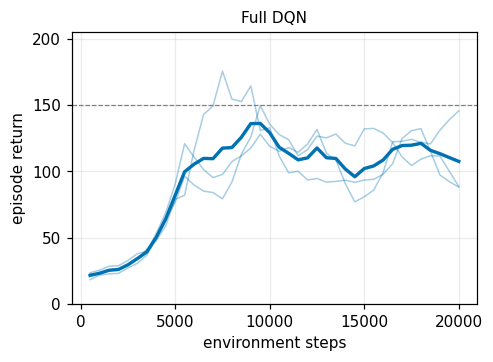

In [13]:
piece_start = time.perf_counter()
results["runs"]["dqn_full"] = {str(seed): train_dqn(seed, **DQN_CONFIGS["dqn_full"]) for seed in SEEDS}
results["piece_seconds"]["dqn"] = time.perf_counter() - piece_start
print_run_table("dqn_full")
print(f"piece 2 took {results['piece_seconds']['dqn']:.1f} s")
save_results(results)
show_curves(["dqn_full"], {"dqn_full": "Full DQN"}, {"dqn_full": "#0072B2"})

Full DQN finished at 88.7, 145.6 and 88.3. That's a wide spread, and the final number hides a lot:

- **Steps to 150:** only seed 2 got there, at step 7,500, and it fell back to 88 by the end. Seed 0 peaked at 149.6, just under.
- **Shape:** all three curves rise until around step 6,000 to 9,000 and then sag instead of climbing steadily.
- **Q-values:** they rose steadily to about 55, and the largest ever was 58 to 61. That's well under the bound of 100 and under 86.6, the most a 200-step episode is worth, so the Q-values are believable.

The module reported 78, 144 and 121 at 30,000 steps, so lower numbers at 20,000 aren't a sign of a bug on their own.

## Piece 3: break it one piece at a time

Now I remove one part of DQN at a time to see what each part is doing:

- **No target network:** targets come from the network being trained.
- **No replay:** train on the latest 64 transitions instead of a random sample from the buffer.
- **Buffer of 1,000 (extra):** replay, but only from the last 1,000 steps.

My prediction and decision rule are in the README, committed before this section ran.

In [14]:
import itertools

AGENTS = ["dqn_full", "dqn_no_target", "dqn_no_replay", "dqn_buffer_1000", "reinforce", "ppo"]
AGENT_LABELS = {"dqn_full": "Full DQN", "dqn_no_target": "DQN, no target network",
                "dqn_no_replay": "DQN, no replay (latest 64)", "dqn_buffer_1000": "DQN, buffer of 1,000",
                "reinforce": "REINFORCE + baseline", "ppo": "PPO"}
COLORS = {"dqn_full": "#0072B2", "dqn_no_target": "#D55E00", "dqn_no_replay": "#E69F00",
          "dqn_buffer_1000": "#CC79A7", "reinforce": "#009E73", "ppo": "#56B4E9"}
DQN_AGENTS = ["dqn_full", "dqn_no_target", "dqn_no_replay", "dqn_buffer_1000"]
RULE_TEXT = ("Two configurations differ on a measure only if their three per-seed values do not overlap: every seed of one is "
             "strictly better than every seed of the other (final return: lowest of one above highest of the other; steps to 150 and "
             "wall-clock: slowest of one below fastest of the other). A seed that never reaches 150 counts as slower than any seed "
             "that does; two seeds that never reach it are tied. Equal endpoints count as overlap. Anything else is cannot tell.")

def compare_pair(values_a, values_b, higher_is_better):
    """The rule committed in the README before this table existed: two configurations differ on a measure
    only if their per-seed ranges do not overlap (strict). None (never reached) counts as +inf for steps.
    Returns 'A better', 'B better' or 'cannot tell'."""
    a = [math.inf if v is None else v for v in values_a]
    b = [math.inf if v is None else v for v in values_b]
    if higher_is_better:
        if min(a) > max(b): return "A better"
        if min(b) > max(a): return "B better"
    else:
        if max(a) < min(b): return "A better"
        if max(b) < min(a): return "B better"
    return "cannot tell"

dqn_full: per seed
seed   final  to 150  episodes  updates  copies trunc-only  mean max-Q@20k  max|Q| ever  wall s
   0    88.7   never       272    19501      79         10            54.9         58.4    24.3
   1   145.6   never       248    19501      79          5            54.7         58.1    23.3
   2    88.3    7500       263    19501      79         17            55.8         61.1    23.5
   above the bound of 100 (max |Q| ever > 100): [False, False, False]
   seed 0: mean max-Q first > 100 at never, max|Q| first > 100 at never, mean max-Q readings 2.14 ... 54.9, non-finite readings at steps none
   seed 1: mean max-Q first > 100 at never, max|Q| first > 100 at never, mean max-Q readings 2.17 ... 54.7, non-finite readings at steps none
   seed 2: mean max-Q first > 100 at never, max|Q| first > 100 at never, mean max-Q readings 2.04 ... 55.8, non-finite readings at steps none
dqn_no_target: per seed
seed   final  to 150  episodes  updates  copies trunc-only  mean max-Q@20k  m

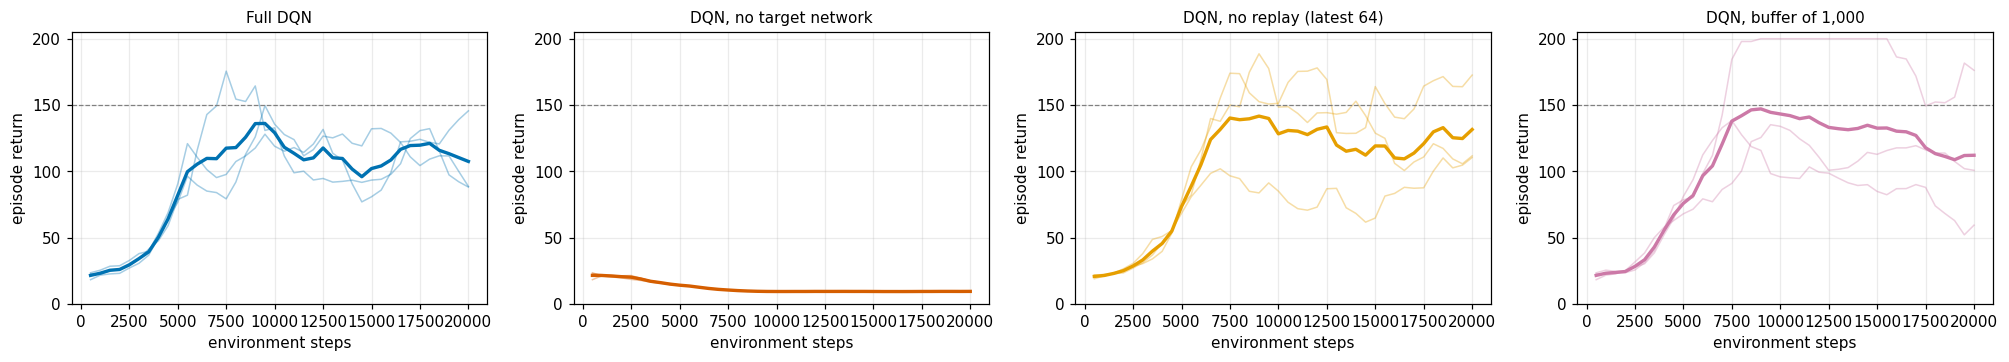

In [15]:
piece_start = time.perf_counter()
for config in ["dqn_no_target", "dqn_no_replay", "dqn_buffer_1000"]:
    results["runs"][config] = {str(seed): train_dqn(seed, **DQN_CONFIGS[config]) for seed in SEEDS}
results["piece_seconds"]["ablations"] = time.perf_counter() - piece_start
for config in DQN_AGENTS:
    print_run_table(config)
    print("   above the bound of 100 (max |Q| ever > 100):",
          [bool(results["runs"][config][str(seed)]["max_abs_q_ever"] > Q_BOUND) for seed in SEEDS])
    for seed in SEEDS:
        q_info = results["runs"][config][str(seed)]["q_probe"]
        mean_max = np.array(q_info["mean_max_q"], dtype=float); max_abs = np.array(q_info["max_abs_q"], dtype=float)
        first_mean_over = next((q_info["steps"][i] for i in range(len(mean_max)) if mean_max[i] > Q_BOUND), None)
        first_abs_over = next((q_info["steps"][i] for i in range(len(max_abs)) if max_abs[i] > Q_BOUND), None)
        bad = [q_info["steps"][i] for i in range(len(mean_max)) if not (np.isfinite(mean_max[i]) and np.isfinite(max_abs[i]))]
        print(f"   seed {seed}: mean max-Q first > 100 at {fmt(first_mean_over, 'd')}, max|Q| first > 100 at {fmt(first_abs_over, 'd')}, "
              f"mean max-Q readings {mean_max[0]:.3g} ... {mean_max[-1]:.3g}, non-finite readings at steps {bad if bad else 'none'}")
print(f"piece 3 took {results['piece_seconds']['ablations']:.1f} s")
save_results(results)
show_curves(DQN_AGENTS, AGENT_LABELS, COLORS)

Here's how my prediction held up.

**No target network: right direction, wrong size.** It collapsed: final returns of 9.6, 9.6 and 9.7, worse than the random policy (22.2), with episodes of about 11 steps. Q was already above 100 at the first reading at step 1,000 and kept growing to about 1e7, with the largest values near 7e7. I'd predicted 1e3 to 1e6, so I was off by about two orders of magnitude. The module saw the same kind of collapse.

**No replay: wrong.** I predicted it would hurt. It didn't: final returns of 111.7, 110.5 and 172.6 against full DQN's 88.7, 145.6 and 88.3, and two seeds reached 150. My Q prediction did hold (it stayed under 100, peaking at 60 to 64). The ranges overlap, so I can't say it's better than full DQN, and I didn't test why it works.

**Buffer of 1,000: partly right.** Final returns of 100.8, 59.5 and 176.2, two of them inside my 60 to 130, with Q under 100. I expected it to be a bit worse than full DQN, but the spread between its own seeds is bigger than any gap between the setups.

In [16]:
print(f"{'config':18s} {'uses per stored transition':>27s} {'steps a transition stays eligible':>35s}")
reuse = {}
eligible = {"dqn_full": "until the end of the run (up to 19,500 steps)", "dqn_no_target": "until the end of the run (up to 19,500 steps)",
            "dqn_no_replay": "64 steps", "dqn_buffer_1000": "1,000 steps"}
for config in DQN_AGENTS:
    n_updates = results["runs"][config]["0"]["n_updates"]
    reuse[config] = n_updates * DQN_SETTINGS["batch_size"] / BUDGET
    print(f"{config:18s} {reuse[config]:27.1f} {eligible[config]:>35s}")
results.setdefault("comparison", {})["reuse_per_transition"] = reuse

config              uses per stored transition   steps a transition stays eligible
dqn_full                                  62.4 until the end of the run (up to 19,500 steps)
dqn_no_target                             62.4 until the end of the run (up to 19,500 steps)
dqn_no_replay                             63.8                            64 steps
dqn_buffer_1000                           62.4                         1,000 steps


I worked out how often each transition is used instead of assuming it. The surprise is no replay: as the handout defines it (latest 64, one update per step), each transition gets used about 64 times in a row, not once. So:

- **No replay** isn't "use once and throw away". This lab never actually tests that.
- **Buffer of 1,000 against no replay** has about the same reuse (62.4 against 63.8), so it tests random against consecutive samples.
- **Buffer of 1,000 against full DQN** tests how old and varied the data is.

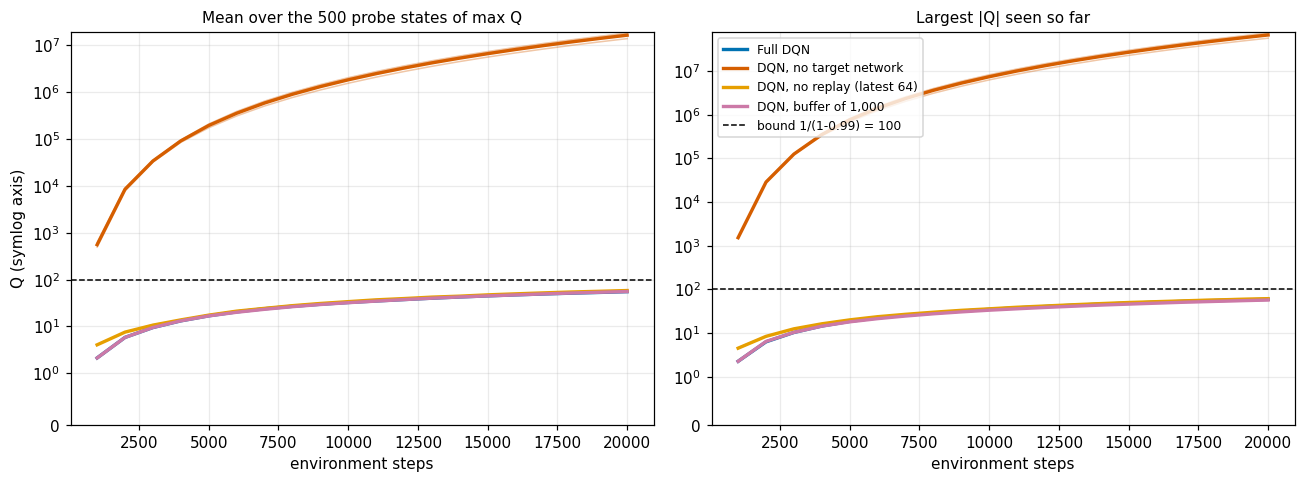

pair                                                       verdict on max |Q| ever
Full DQN vs DQN, no target network                         DQN, no target network larger   (['58.4', '58.1', '61.1'] vs ['5.68e+07', '7.47e+07', '7.03e+07'])
Full DQN vs DQN, no replay (latest 64)                     cannot tell   (['58.4', '58.1', '61.1'] vs ['60.3', '63.9', '59.7'])
Full DQN vs DQN, buffer of 1,000                           Full DQN larger   (['58.4', '58.1', '61.1'] vs ['57.6', '58', '55.6'])
DQN, no target network vs DQN, no replay (latest 64)       DQN, no target network larger   (['5.68e+07', '7.47e+07', '7.03e+07'] vs ['60.3', '63.9', '59.7'])
DQN, no target network vs DQN, buffer of 1,000             DQN, no target network larger   (['5.68e+07', '7.47e+07', '7.03e+07'] vs ['57.6', '58', '55.6'])
DQN, no replay (latest 64) vs DQN, buffer of 1,000         DQN, no replay (latest 64) larger   (['60.3', '63.9', '59.7'] vs ['57.6', '58', '55.6'])
exceeds the bound of 100 on all three s

In [17]:
def q_array(record, field):
    return np.array([np.nan if v is None else v for v in record["q_probe"][field]], dtype=float)

q_steps = np.array(results["runs"]["dqn_full"]["0"]["q_probe"]["steps"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, field, title in [(axes[0], "mean_max_q", "Mean over the 500 probe states of max Q"),
                         (axes[1], "max_abs_q_ever_running", "Largest |Q| seen so far")]:
    for config in DQN_AGENTS:
        curves = np.array([q_array(results["runs"][config][str(seed)], field) for seed in SEEDS])
        curves = np.where(np.isfinite(curves), curves, np.nan)       # plot finite values only
        for seed_curve in curves:
            ax.plot(q_steps, seed_curve, color=COLORS[config], alpha=0.35, lw=1)
        ax.plot(q_steps, np.nanmean(curves, axis=0), color=COLORS[config], lw=2.2, label=AGENT_LABELS[config])
    ax.axhline(Q_BOUND, ls="--", color="black", lw=1, label="bound 1/(1-0.99) = 100")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("environment steps"); ax.set_title(title, fontsize=10); ax.grid(alpha=0.25)
axes[0].set_ylabel("Q (symlog axis)")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
show(fig, "figures/q_probe_vs_bound.png")
for config in DQN_AGENTS:
    for seed in SEEDS:
        for field in ["mean_max_q", "max_abs_q"]:
            values = q_array(results["runs"][config][str(seed)], field)
            if not np.all(np.isfinite(values)):
                print("non-finite Q:", config, "seed", seed, field, "at steps", q_steps[~np.isfinite(values)].tolist())

# the committed rule on the largest |Q| ever seen, for the 6 pairs of DQN configurations (larger = bigger Q)
q_pairs = []
print(f"{'pair':58s} verdict on max |Q| ever")
for name_a, name_b in itertools.combinations(DQN_AGENTS, 2):
    values_a = [results["runs"][name_a][str(seed)]["max_abs_q_ever"] for seed in SEEDS]
    values_b = [results["runs"][name_b][str(seed)]["max_abs_q_ever"] for seed in SEEDS]
    raw = compare_pair(values_a, values_b, higher_is_better=True)
    verdict = AGENT_LABELS[name_a] + " larger" if raw == "A better" else AGENT_LABELS[name_b] + " larger" if raw == "B better" else "cannot tell"
    q_pairs.append({"a": name_a, "b": name_b, "measure": "max_abs_q_ever", "a_values": values_a, "b_values": values_b, "verdict": verdict})
    print(f"{AGENT_LABELS[name_a] + ' vs ' + AGENT_LABELS[name_b]:58s} {verdict}   ({[f'{v:.3g}' for v in values_a]} vs {[f'{v:.3g}' for v in values_b]})")
exceeds_bound = {config: bool(all(results["runs"][config][str(seed)]["max_abs_q_ever"] > Q_BOUND for seed in SEEDS)) for config in DQN_AGENTS}
print("exceeds the bound of 100 on all three seeds:", exceeds_bound)
results.setdefault("comparison", {})["q_pairs"] = q_pairs
results["comparison"]["exceeds_bound"] = exceeds_bound
results["comparison"]["rule"] = RULE_TEXT
save_results(results)

The plot uses a log scale above 1 so values from 1 to 1e7 fit on one axis. Full DQN, no replay and buffer-1000 all climb slowly to about 55 to 60 and stay under the bound (the full-DQN line is hidden under buffer-1000). The no-target run is above 100 from the first reading and keeps climbing. It's the only setup that breaks the bound on all three seeds.

Under my decision rule, no-target has a larger max |Q| than every other setup, and no replay is larger than buffer-1000. Full DQN also comes out larger than buffer-1000, but only by 0.01, which passes only because the rule is strict, so I don't read anything into it.

## Piece 4: policy-gradient agents, same budget

Same 20,000 steps and the same seeds, now with two agents that learn the policy directly:

- **REINFORCE with a baseline:** updates after every 8 full episodes, using the return-to-go and a learned value baseline.
- **PPO:** collects 1,024-step rollouts and takes several clipped minibatch updates on each.

For PPO I also watch the ratio. On the first minibatch of a rollout it has to be exactly 1; if it stays at 1 the whole time, the old log-probabilities are being recomputed by mistake. I record wall-clock time for every agent too.

In [18]:
def train_reinforce(seed, steps=BUDGET, episodes_per_update=8, policy_lr=3e-3, value_lr=1e-2, gamma=0.99):
    """REINFORCE with a learned state-value baseline. One update per 8 complete episodes."""
    start = time.perf_counter()
    S.set_seed(seed)
    env = S.CartPole(seed=seed)
    policy = S.mlp(4, 2)
    value_fn = S.mlp(4, 1)
    policy_optimizer = torch.optim.Adam(policy.parameters(), lr=policy_lr)
    value_optimizer = torch.optim.Adam(value_fn.parameters(), lr=value_lr)
    t, episodes, n_updates, n_dropped_partial_episode = 0, [], 0, 0

    while t < steps:
        batch_states, batch_actions, batch_returns = [], [], []
        n_complete = 0
        while n_complete < episodes_per_update and t < steps:
            state = env.reset()
            episode_states, episode_actions, episode_rewards = [], [], []
            while True:
                with torch.no_grad():
                    action = int(torch.distributions.Categorical(logits=policy(torch.as_tensor(state)[None])).sample())
                next_state, reward, terminated, truncated = env.step(action)
                t += 1
                episode_states.append(state); episode_actions.append(action); episode_rewards.append(reward)
                state = next_state
                if terminated or truncated:
                    episodes.append((t, float(sum(episode_rewards))))
                    batch_states += episode_states; batch_actions += episode_actions
                    batch_returns += list(returns_to_go(episode_rewards, gamma))
                    n_complete += 1
                    break
                elif t == steps:                       # cut by the budget: not logged, not trained on
                    n_dropped_partial_episode += 1
                    break
        if n_complete == episodes_per_update and t < steps:
            batch_states = torch.as_tensor(np.array(batch_states, np.float32))
            batch_actions = torch.as_tensor(np.array(batch_actions, np.int64))
            batch_returns = torch.as_tensor(np.array(batch_returns, np.float32))
            values = value_fn(batch_states)[:, 0]                 # pre-update baseline
            advantages = batch_returns - values.detach()
            value_loss = F.mse_loss(values, batch_returns)
            value_optimizer.zero_grad(); value_loss.backward(); value_optimizer.step()
            advantages = advantages / (advantages.std() + 1e-8)   # divided by std, NOT mean-centred (handout wording)
            log_probs = torch.distributions.Categorical(logits=policy(batch_states)).log_prob(batch_actions)
            policy_loss = -(log_probs * advantages).mean()
            policy_optimizer.zero_grad(); policy_loss.backward(); policy_optimizer.step(); n_updates += 1

    wall_seconds = time.perf_counter() - start
    assert t == steps, t
    assert all(episode_end <= steps for episode_end, _ in episodes)
    return make_run_record(episodes, wall_seconds, n_updates=n_updates, n_dropped_partial_episode=n_dropped_partial_episode)

def train_ppo(seed, steps=BUDGET, rollout_steps=1024, epochs=6, minibatch_size=128, clip=0.2, gamma=0.99,
              lam=0.95, learning_rate=3e-4, value_coef=0.5, grad_clip=0.5, entropy_coef=0.0):
    """PPO with GAE. Rollouts of 1,024 steps; the last one is shortened so the total is exactly `steps`."""
    start = time.perf_counter()
    S.set_seed(seed)
    env = S.CartPole(seed=seed)
    policy = S.mlp(4, 2)
    value_fn = S.mlp(4, 1)
    all_params = list(policy.parameters()) + list(value_fn.parameters())
    optimizer = torch.optim.Adam(all_params, lr=learning_rate)
    state = env.reset()
    episode_return = 0.0
    t, episodes, n_updates, n_rollouts, last_rollout_length = 0, [], 0, 0, 0
    first_minibatch_ratio_gap, last_minibatch_ratio_gap, clip_fractions = [], [], []

    while t < steps:
        n = min(rollout_steps, steps - t)
        states = np.zeros((n, 4), np.float32); actions = np.zeros(n, np.int64); rewards = np.zeros(n, np.float32)
        terminated_flags = np.zeros(n, np.float32); ended_flags = np.zeros(n, np.float32)
        values = np.zeros(n, np.float32); next_values = np.zeros(n, np.float32); old_log_probs = np.zeros(n, np.float32)
        for i in range(n):
            state_tensor = torch.as_tensor(state)[None]
            with torch.no_grad():
                dist = torch.distributions.Categorical(logits=policy(state_tensor))
                action = dist.sample()
                values[i] = value_fn(state_tensor)[0, 0]
                old_log_probs[i] = dist.log_prob(action)            # frozen at collection time
            next_state, reward, terminated, truncated = env.step(int(action))
            t += 1
            states[i], actions[i], rewards[i] = state, int(action), reward
            terminated_flags[i] = float(terminated); ended_flags[i] = float(terminated or truncated)
            with torch.no_grad():
                next_values[i] = value_fn(torch.as_tensor(next_state)[None])[0, 0]   # true next state, before any reset
            episode_return += reward
            if terminated or truncated:
                episodes.append((t, episode_return)); episode_return = 0.0
                state = env.reset()
            else:
                state = next_state
        n_rollouts += 1
        last_rollout_length = n
        if t >= steps:                                                # the final short rollout is not trained on
            break

        advantages = gae_advantages(rewards, values, next_values, terminated_flags, ended_flags, gamma, lam)
        value_targets = advantages + values                           # from the collection-time value function
        advantages_t = torch.as_tensor(advantages)
        value_targets_t = torch.as_tensor(value_targets)
        old_log_probs_t = torch.as_tensor(old_log_probs)
        assert not old_log_probs_t.requires_grad
        advantages_t = (advantages_t - advantages_t.mean()) / (advantages_t.std() + 1e-8)   # once per rollout
        states_t, actions_t = torch.as_tensor(states), torch.as_tensor(actions)

        clipped_counts, minibatch_count = 0.0, 0
        for epoch in range(epochs):
            permutation = torch.randperm(n)
            for start_index in range(0, n, minibatch_size):
                indices = permutation[start_index:start_index + minibatch_size]
                dist = torch.distributions.Categorical(logits=policy(states_t[indices]))
                ratio = torch.exp(dist.log_prob(actions_t[indices]) - old_log_probs_t[indices])
                surrogate = ppo_clip_objective(ratio, advantages_t[indices], clip)
                value_loss = F.mse_loss(value_fn(states_t[indices])[:, 0], value_targets_t[indices])
                loss = -surrogate.mean() + value_coef * value_loss - entropy_coef * dist.entropy().mean()
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(all_params, grad_clip)
                optimizer.step(); n_updates += 1
                ratio_gap = (ratio.detach() - 1.0).abs()
                clipped_counts += float((ratio_gap > clip).float().mean()); minibatch_count += 1
                if epoch == 0 and start_index == 0:
                    first_minibatch_ratio_gap.append(float(ratio_gap.max()))
                    assert first_minibatch_ratio_gap[-1] < 1e-5, "ratio must be 1 before the first step of a rollout"
                if epoch == epochs - 1 and start_index + minibatch_size >= n:
                    last_minibatch_ratio_gap.append(float(ratio_gap.mean()))
        clip_fractions.append(clipped_counts / minibatch_count)

    wall_seconds = time.perf_counter() - start
    assert t == steps, t
    assert n_rollouts == math.ceil(steps / rollout_steps), n_rollouts
    assert last_rollout_length == steps - (n_rollouts - 1) * rollout_steps
    assert n_updates == (n_rollouts - 1) * epochs * math.ceil(rollout_steps / minibatch_size), n_updates
    assert max(last_minibatch_ratio_gap) > 1e-6, "the ratio never moved off 1: old log-probs are being recomputed"
    assert all(episode_end <= steps for episode_end, _ in episodes)
    return make_run_record(episodes, wall_seconds, n_updates=n_updates, n_rollouts=n_rollouts,
                           final_rollout_steps=last_rollout_length,
                           first_minibatch_max_abs_ratio_minus_1=first_minibatch_ratio_gap,
                           last_minibatch_mean_abs_ratio_minus_1=last_minibatch_ratio_gap,
                           clip_fraction=clip_fractions)

reinforce: per seed
seed   final  to 150  episodes  updates  copies trunc-only  mean max-Q@20k  max|Q| ever  wall s
   0   196.2   13000       213       26                                                     4.1
   1   174.5   12000       215       26                                                     3.9
   2   146.7   13500       223       27                                                     4.1
ppo: per seed
seed   final  to 150  episodes  updates  copies trunc-only  mean max-Q@20k  max|Q| ever  wall s
   0   133.2   10500       284      912                                                     9.9
   1   186.7   10500       240      912                                                     9.4
   2   178.2   11000       255      912                                                     9.5
PPO seed 0: mean clip fraction 0.037, largest first-minibatch |ratio-1| 7.15e-07, mean last-minibatch |ratio-1| (min/max over rollouts) 0.0247/0.1228, rollouts 20, last rollout 544 steps
PPO seed 1:

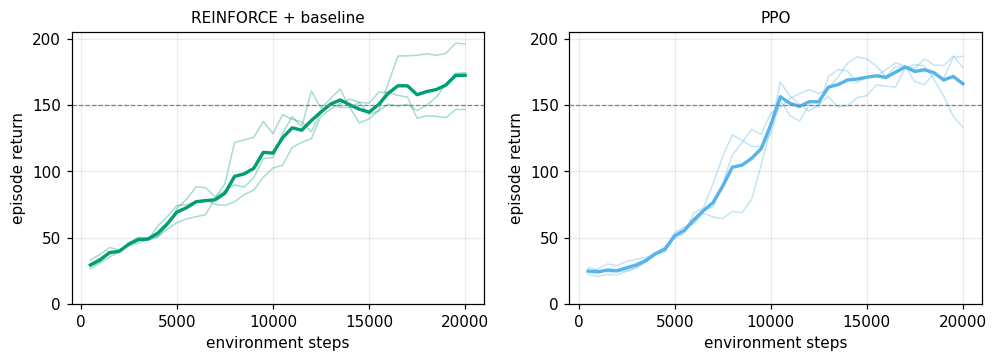

In [19]:
piece_start = time.perf_counter()
for seed in SEEDS:
    results["runs"].setdefault("reinforce", {})[str(seed)] = train_reinforce(seed, **REINFORCE_SETTINGS)
    results["runs"].setdefault("ppo", {})[str(seed)] = train_ppo(seed, **PPO_SETTINGS)
results["piece_seconds"]["policy_gradient"] = time.perf_counter() - piece_start
print_run_table("reinforce")
print_run_table("ppo")
for seed in SEEDS:
    ppo_record = results["runs"]["ppo"][str(seed)]
    print(f"PPO seed {seed}: mean clip fraction {np.mean(ppo_record['clip_fraction']):.3f}, "
          f"largest first-minibatch |ratio-1| {max(ppo_record['first_minibatch_max_abs_ratio_minus_1']):.2e}, "
          f"mean last-minibatch |ratio-1| (min/max over rollouts) {min(ppo_record['last_minibatch_mean_abs_ratio_minus_1']):.4f}/"
          f"{max(ppo_record['last_minibatch_mean_abs_ratio_minus_1']):.4f}, rollouts {ppo_record['n_rollouts']}, last rollout {ppo_record['final_rollout_steps']} steps")
for seed in SEEDS:
    print(f"REINFORCE seed {seed}: updates {results['runs']['reinforce'][str(seed)]['n_updates']}, "
          f"dropped partial episodes {results['runs']['reinforce'][str(seed)]['n_dropped_partial_episode']}")
print(f"piece 4 took {results['piece_seconds']['policy_gradient']:.1f} s")
save_results(results)
show_curves(["reinforce", "ppo"], {"reinforce": "REINFORCE + baseline", "ppo": "PPO"},
            {"reinforce": "#009E73", "ppo": "#56B4E9"})

Both agents beat full DQN on the mean.

- **REINFORCE:** finished at 196.2, 174.5 and 146.7, and reached 150 at steps 12,000 to 13,500. It only made 26 or 27 updates, because it waits for 8 full episodes and the episodes get long.
- **PPO:** finished at 133.2, 186.7 and 178.2 and reached 150 sooner, at steps 10,500 to 11,000. It made 912 updates.
- **PPO's ratio:** exactly 1 (within 7e-7) on the first minibatch of every rollout, and off 1 by the last one, with about 3% of samples clipped. So the old log-probabilities are being kept properly.
- **Cost:** REINFORCE took about 4 s a run, PPO about 10 s and DQN about 24 s, because DQN updates on every step.

The module's numbers at 30,000 steps (REINFORCE 171, 188, 191; PPO 188, 182, 183) are in the same range.

## Piece 5: all six agents under the decision rule

The rule is in the README and was committed before I looked at this table: two agents only count as different on a measure if none of their three seeds overlap. Otherwise it's "cannot tell". I apply it to all 15 pairs on final return, steps to 150 and wall-clock time.

In [20]:
summary = {}
for agent in AGENTS:
    records = [results["runs"][agent][str(seed)] for seed in SEEDS]
    summary[agent] = {"final_return": [r["final_return"] for r in records],
                      "steps_to_150": [r["steps_to_150"] for r in records],
                      "wall_seconds": [r["wall_seconds"] for r in records]}
print(f"{'agent':28s} {'final return (seeds 0/1/2)':>30s} {'min-max':>13s}  {'steps to 150':>26s}  {'wall s':>20s}")
for agent in AGENTS:
    s = summary[agent]
    finals = " / ".join(f"{v:5.1f}" for v in s["final_return"])
    steps = " / ".join(f"{fmt(v, 'd'):>5s}" for v in s["steps_to_150"])
    walls = " / ".join(f"{v:5.1f}" for v in s["wall_seconds"])
    print(f"{AGENT_LABELS[agent]:28s} {finals:>30s} {min(s['final_return']):5.1f}-{max(s['final_return']):5.1f}  {steps:>26s}  {walls:>20s}")

MEASURES = [("final_return", True), ("steps_to_150", False), ("wall_seconds", False)]
pairs = []
for agent_a, agent_b in itertools.combinations(AGENTS, 2):
    for measure, higher_is_better in MEASURES:
        values_a, values_b = summary[agent_a][measure], summary[agent_b][measure]
        raw = compare_pair(values_a, values_b, higher_is_better)
        verdict = AGENT_LABELS[agent_a] if raw == "A better" else AGENT_LABELS[agent_b] if raw == "B better" else "cannot tell"
        pairs.append({"a": agent_a, "b": agent_b, "measure": measure, "a_values": values_a, "b_values": values_b, "verdict": verdict})
print()
print(f"{'pair':56s} {'final return':>28s} {'steps to 150':>28s} {'wall-clock':>28s}")
for agent_a, agent_b in itertools.combinations(AGENTS, 2):
    row = {p["measure"]: p["verdict"] for p in pairs if p["a"] == agent_a and p["b"] == agent_b}
    print(f"{AGENT_LABELS[agent_a] + ' vs ' + AGENT_LABELS[agent_b]:56s} {row['final_return']:>28s} {row['steps_to_150']:>28s} {row['wall_seconds']:>28s}")
counts = {measure: sum(1 for p in pairs if p["measure"] == measure and p["verdict"] != "cannot tell") for measure, _ in MEASURES}
print()
for measure, _ in MEASURES:
    print(f"{counts[measure]} of 15 pairs differ on {measure}")
comparison = results.setdefault("comparison", {})
comparison.update({"rule": RULE_TEXT, "summary": summary, "pairs": pairs, "counts": counts})
save_results(results)

agent                            final return (seeds 0/1/2)       min-max                steps to 150                wall s
Full DQN                               88.7 / 145.6 /  88.3  88.3-145.6       never / never /  7500   24.3 /  23.3 /  23.5
DQN, no target network                  9.6 /   9.6 /   9.7   9.6-  9.7       never / never / never   23.2 /  24.0 /  23.9
DQN, no replay (latest 64)            111.7 / 110.5 / 172.6 110.5-172.6        7500 / never /  7000   24.5 /  24.6 /  24.5
DQN, buffer of 1,000                  100.8 /  59.5 / 176.2  59.5-176.2       never / never /  7500   24.3 /  24.2 /  24.5
REINFORCE + baseline                  196.2 / 174.5 / 146.7 146.7-196.2       13000 / 12000 / 13500    4.1 /   3.9 /   4.1
PPO                                   133.2 / 186.7 / 178.2 133.2-186.7       10500 / 10500 / 11000    9.9 /   9.4 /   9.5

pair                                                                     final return                 steps to 150                   wall

Most pairs come out as "cannot tell", which is what I'd expect with three seeds and curves that cross.

- **Final return:** 6 of 15 pairs differ. Five of those are just other agents beating the no-target run. The only other one is REINFORCE over full DQN, by a margin of 1.1 (146.7 against 145.6).
- **Steps to 150:** only 3 pairs differ: REINFORCE and PPO against the no-target run, and PPO against REINFORCE.
- **Wall-clock:** 12 pairs differ. The 9 involving a policy-gradient agent are real gaps. The other 3 are DQN variants about a second apart on 24 s of identical work, and an earlier run of the same notebook flagged different pairs, so I treat those as timing noise.

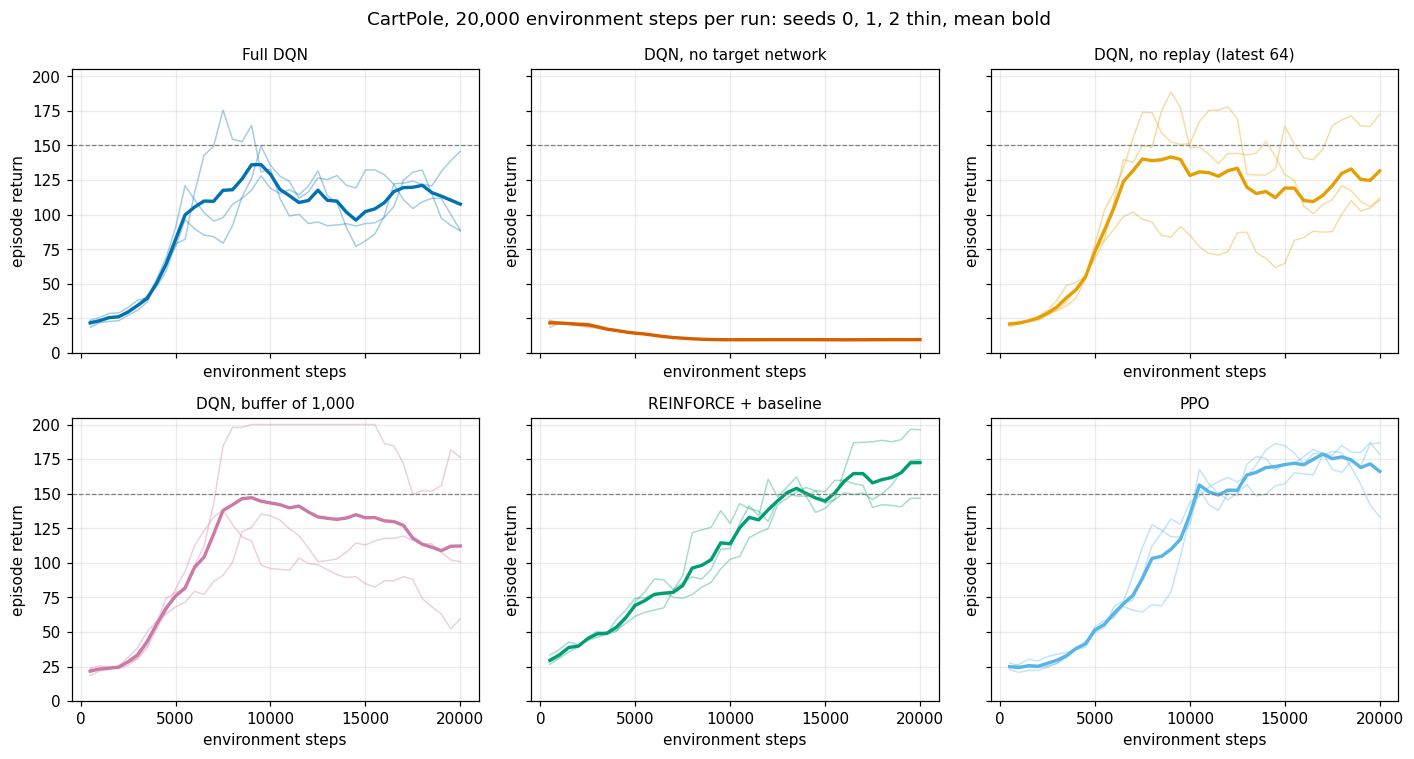

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for ax, agent in zip(axes.flat, AGENTS):
    S.plot_curves(ax, {seed: curve_array(results["runs"][agent][str(seed)]) for seed in SEEDS},
                  AGENT_LABELS[agent], color=COLORS[agent])
    ax.axhline(LEVEL, ls="--", lw=0.8, color="grey")
fig.suptitle("CartPole, 20,000 environment steps per run: seeds 0, 1, 2 thin, mean bold")
fig.tight_layout()
show(fig, "figures/learning_curves_all_agents.png")

In the figure the no-target panel is flat at the bottom, full DQN and buffer-1000 rise to 100 to 150 and then sag, no replay holds around 130, and REINFORCE and PPO end around 165 to 175. The policy-gradient curves are much smoother. Buffer-1000 shows why one final number isn't enough: seed 2 sat near 200 for thousands of steps before ending at 176, while another seed ended at 59.5.

## Save the numbers

In [22]:
results["total_seconds"] = time.perf_counter() - notebook_start
save_results(results)
print(f"whole notebook: {results['total_seconds'] / 60:.1f} minutes on {torch.get_num_threads()} CPU thread, torch {torch.__version__}")

whole notebook: 5.7 minutes on 1 CPU thread, torch 2.2.2


## Conclusion

- **Best final return:** REINFORCE with a baseline (196.2, 174.5, 146.7). It's the only agent that beats full DQN under my rule, but only just, it was the slowest to reach 150, and I can't separate it from PPO.
- **Quickest to a working policy:** PPO, which reached 150 at steps 10,500 to 11,000 and beat REINFORCE on that measure. Its final return isn't clearly better than anything except the no-target DQN.
- **Cheapest to run:** REINFORCE at about 4 s, then PPO at about 10 s, against about 24 s for every DQN variant.
- **Full DQN:** I wouldn't pick it for this task. It only beat its own broken version. In its favour, it's the only agent whose Q-values I could check against a known bound.
- **What three seeds can show:** big gaps like the no-target collapse and the policy-gradient speed advantage. **What they can't:** an order among full DQN, no replay and buffer-1000, or anything about other tasks, budgets or settings.